In [ ]:
#Part A – Question 1: Data Understanding

In [ ]:
#Step 1 – Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
#Step 2 – Load the Dataset

In [2]:
train_df = pd.read_csv("DailyDelhiClimateTrain.csv")

test_df = pd.read_csv("DailyDelhiClimateTest.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
#Step 3 – Display First 10 Rows

In [3]:
train_df.head(10)

,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000
5,2013-01-06,7.000000,82.800000,1.480000,1018.000000
6,2013-01-07,7.000000,78.600000,6.300000,1020.000000
7,2013-01-08,8.857143,63.714286,7.142857,1018.714286
8,2013-01-09,14.000000,51.250000,12.500000,1017.000000
9,2013-01-10,11.000000,62.000000,7.400000,1015.666667


In [ ]:
#Step 4 – Check Dataset Information

In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          1462 non-null   object 
 1   meantemp      1462 non-null   float64
 2   humidity      1462 non-null   float64
 3   wind_speed    1462 non-null   float64
 4   meanpressure  1462 non-null   float64
dtypes: float64(4), object(1)
memory usage: 57.2+ KB


In [ ]:
#Step 5 – Check Missing Values

In [5]:
train_df.isnull().sum()

date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

In [ ]:
#Step 6 – Plot Temperature Trends Over Time

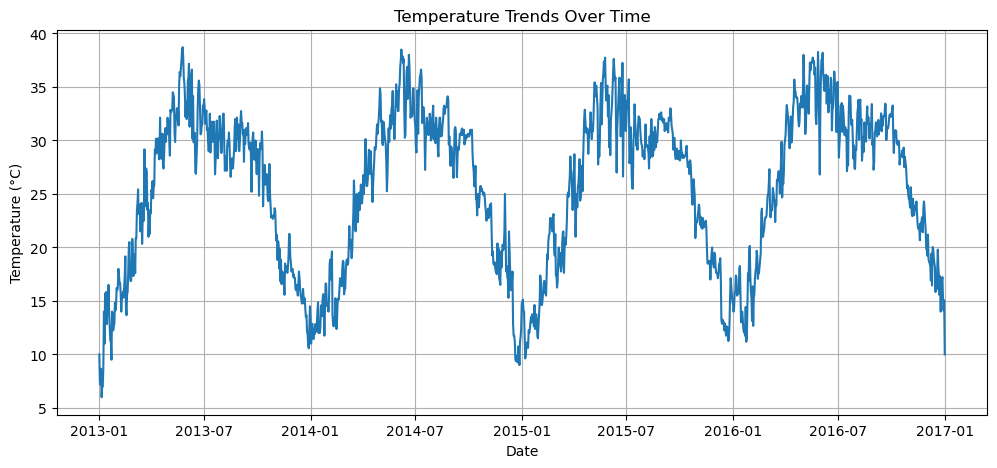

In [6]:
train_df['date'] = pd.to_datetime(train_df['date'])

plt.figure(figsize=(12, 5))

plt.plot(train_df['date'], train_df['meantemp'])

plt.title('Temperature Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')

plt.grid(True)
plt.show()

In [ ]:
#Part A – Question 2: Data Preprocessing

In [ ]:
#Step 7 – Convert Date Column

In [7]:
train_df = train_df.sort_values('date')

train_df = train_df.reset_index(drop=True)

print("Date sorted successfully!")

Date sorted successfully!


In [ ]:
#Step 8 – Check Missing Values Again

In [8]:
train_df.isnull().sum()

date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

In [ ]:
#Step 9 – Select Features

In [9]:
features = train_df[['meantemp', 'humidity', 'wind_speed']]

target = train_df['meantemp']

print("Features selected successfully!")

Features selected successfully!


In [ ]:
#Step 10 – Normalize Data using MinMaxScaler

In [ ]:
#Step 10.1 – Import MinMaxScaler

In [10]:
from sklearn.preprocessing import MinMaxScaler

print("MinMaxScaler imported successfully!")

MinMaxScaler imported successfully!


In [ ]:
#Step 11 – Split Dataset

In [11]:
split_index = int(len(train_df) * 0.8)

train_data = train_df.iloc[:split_index]
val_data = train_df.iloc[split_index:]

print("Training data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)

Training data shape: (1169, 5)
Validation data shape: (293, 5)


In [ ]:
#Step 12 – Scale the Features

In [12]:
scaler = MinMaxScaler()

X_train = scaler.fit_transform(
    train_data[['meantemp', 'humidity', 'wind_speed']]
)

X_val = scaler.transform(
    val_data[['meantemp', 'humidity', 'wind_speed']]
)

print("Training data scaled:", X_train.shape)
print("Validation data scaled:", X_val.shape)

Training data scaled: (1169, 3)
Validation data scaled: (293, 3)


In [ ]:
#Step 13 – Create Sequences (Past 7 Days).

In [14]:
def create_sequences(data, sequence_length=7):

    X = []
    y = []

    for i in range(sequence_length, len(data)):

        X.append(data[i-sequence_length:i, :])

        y.append(data[i, 0])

    return np.array(X), np.array(y)

In [15]:
X_train_seq, y_train_seq = create_sequences(X_train)

print("X_train sequence shape:", X_train_seq.shape)
print("y_train sequence shape:", y_train_seq.shape)

X_train sequence shape: (1162, 7, 3)
y_train sequence shape: (1162,)


In [ ]:
#Step 14 – Create Validation Sequences

In [16]:
X_val_seq, y_val_seq = create_sequences(X_val)

print("X_val sequence shape:", X_val_seq.shape)
print("y_val sequence shape:", y_val_seq.shape)

X_val sequence shape: (286, 7, 3)
y_val sequence shape: (286,)


In [ ]:
#Step 15 – Build SimpleRNN Model

In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

print("TensorFlow and Keras imported successfully!")

TensorFlow and Keras imported successfully!


In [ ]:
#Step 16 – Build SimpleRNN Model.

In [19]:
model = Sequential([
    tf.keras.Input(shape=(7, 3)),
    SimpleRNN(64, activation='tanh'),
    Dropout(0.2),
    Dense(1)
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Step 17 – Compile the Model

In [20]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
#Step 18 – Train the Model

In [21]:
history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=50,
    batch_size=32
)

Epoch 1/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0644 - mae: 0.1908 - val_loss: 0.0049 - val_mae: 0.0569
Epoch 2/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0161 - mae: 0.1008 - val_loss: 0.0039 - val_mae: 0.0493
Epoch 3/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0116 - mae: 0.0841 - val_loss: 0.0034 - val_mae: 0.0454
Epoch 4/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0107 - mae: 0.0815 - val_loss: 0.0033 - val_mae: 0.0457
Epoch 5/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0088 - mae: 0.0737 - val_loss: 0.0035 - val_mae: 0.0475
Epoch 6/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0086 - mae: 0.0733 - val_loss: 0.0048 - val_mae: 0.0569
Epoch 7/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0073 - mae: 0.0685 - val_loss: 0.0033 - val_mae: 0.0441
Epoch 8/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0069 - mae: 0.0646 - val_loss: 0.0032 - val_mae: 0.0448
Epoch 9/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0061 - mae:

In [ ]:
#Step 19 – Plot Training and Validation Loss

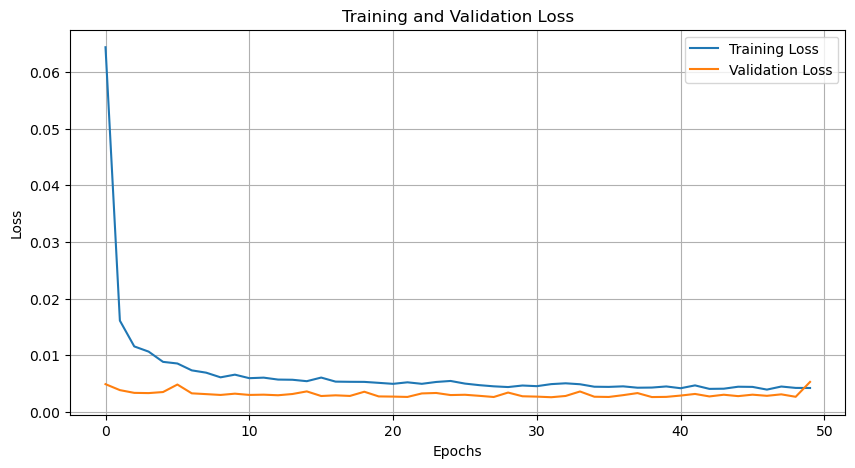

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Part C – Model Evaluation

In [ ]:
#Step 20 – Load Test Dataset

In [23]:
test_features = test_df[['meantemp', 'humidity', 'wind_speed']]

X_test = scaler.transform(test_features)

print("Test data scaled successfully!")
print("Test data shape:", X_test.shape)

Test data scaled successfully!
Test data shape: (114, 3)


In [ ]:
#Step 21 – Create Test Sequences

In [24]:
X_test_seq, y_test_seq = create_sequences(X_test)

print("Test sequence shape:", X_test_seq.shape)
print("Test target shape:", y_test_seq.shape)

Test sequence shape: (107, 7, 3)
Test target shape: (107,)


In [ ]:
#Step 22 – Predict Temperature

In [25]:
y_pred = model.predict(X_test_seq)

print("Predictions completed!")
print("Predicted values shape:", y_pred.shape)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step
Predictions completed!
Predicted values shape: (107, 1)


In [ ]:
#Step 23 – Calculate RMSE, MAE and R²

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rmse = np.sqrt(mean_squared_error(y_test_seq, y_pred))
mae = mean_absolute_error(y_test_seq, y_pred)
r2 = r2_score(y_test_seq, y_pred)

print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

RMSE: 0.06453986224465626
MAE: 0.05297041878947656
R2 Score: 0.8921502616067568


In [ ]:
#Step 24 – Compare Actual vs Predicted Temperature

In [27]:
results = pd.DataFrame({
    'Actual Temperature': y_test_seq,
    'Predicted Temperature': y_pred.flatten()
})

results.head(10)

,Actual Temperature,Predicted Temperature
0,0.296024,0.251715
1,0.262009,0.276160
2,0.186803,0.262607
3,0.152838,0.176219
4,0.176971,0.162983
5,0.221166,0.179603
6,0.220087,0.190654
7,0.318967,0.199304
8,0.264410,0.275804
9,0.174915,0.244123


In [ ]:
#Step 25 – Actual vs Predicted Temperature Graph

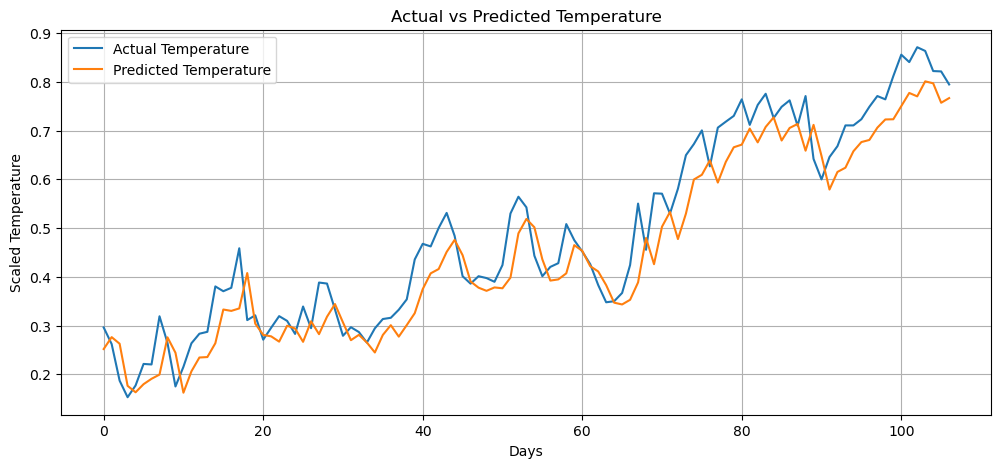

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_seq, label='Actual Temperature')
plt.plot(y_pred, label='Predicted Temperature')

plt.title('Actual vs Predicted Temperature')
plt.xlabel('Days')
plt.ylabel('Scaled Temperature')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Step 26 – Forecast Next 7 Days Temperature

In [30]:
last_sequence = X_test[-7:].copy()

future_predictions = []

for i in range(7):

    prediction = model.predict(
        last_sequence.reshape(1, 7, 3),
        verbose=0
    )

    future_predictions.append(prediction[0, 0])

    new_row = last_sequence[-1].copy()
    new_row[0] = prediction[0, 0]

    last_sequence = np.vstack([
        last_sequence[1:],
        new_row
    ])

print("Next 7 Days Forecast:")
print(future_predictions)

Next 7 Days Forecast:
[np.float32(0.7552261), np.float32(0.71186334), np.float32(0.681465), np.float32(0.6537991), np.float32(0.63053215), np.float32(0.61270595), np.float32(0.5961174)]


In [ ]:
#Step 27 – Forecast Celsius

In [31]:
temp_min = scaler.data_min_[0]
temp_max = scaler.data_max_[0]

future_predictions_c = [
    value * (temp_max - temp_min) + temp_min
    for value in future_predictions
]

print("Next 7 Days Temperature Forecast (°C):")

for day, temp in enumerate(future_predictions_c, start=1):
    print(f"Day {day}: {temp:.2f} °C")

Next 7 Days Temperature Forecast (°C):
Day 1: 30.71 °C
Day 2: 29.29 °C
Day 3: 28.29 °C
Day 4: 27.39 °C
Day 5: 26.63 °C
Day 6: 26.04 °C
Day 7: 25.50 °C


In [ ]:
#Step 28 – Actual vs Predicted Temperature (°C)

In [32]:
y_test_actual_c = (
    y_test_seq * (scaler.data_max_[0] - scaler.data_min_[0])
    + scaler.data_min_[0]
)

y_test_pred_c = (
    y_pred.flatten() * (scaler.data_max_[0] - scaler.data_min_[0])
    + scaler.data_min_[0]
)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rmse_c = np.sqrt(mean_squared_error(y_test_actual_c, y_test_pred_c))
mae_c = mean_absolute_error(y_test_actual_c, y_test_pred_c)
r2_c = r2_score(y_test_actual_c, y_test_pred_c)

print("RMSE (°C):", rmse_c)
print("MAE (°C):", mae_c)
print("R2 Score:", r2_c)

RMSE (°C): 2.1113754934323268
MAE (°C): 1.7328894146843048
R2 Score: 0.8921502616067568


In [ ]:
#Step 30 – Actual vs Predicted Graph (°C)

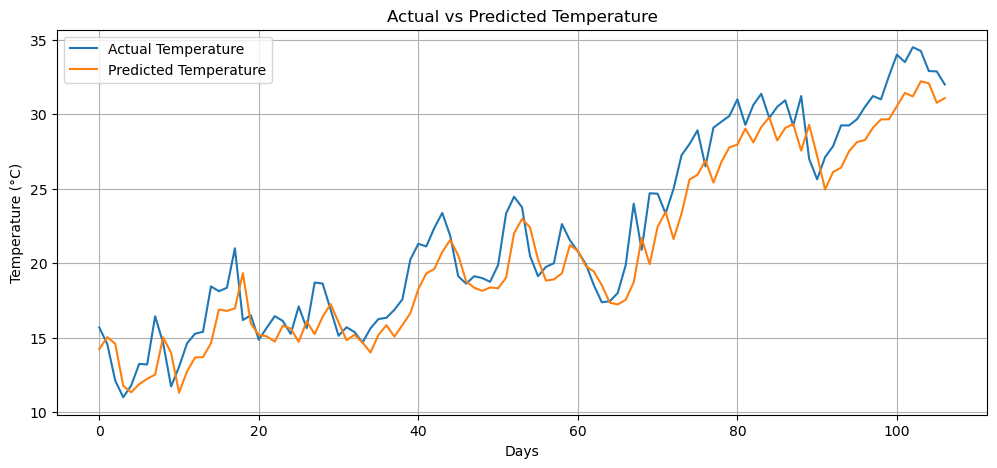

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(y_test_actual_c, label='Actual Temperature')
plt.plot(y_test_pred_c, label='Predicted Temperature')

plt.title('Actual vs Predicted Temperature')
plt.xlabel('Days')
plt.ylabel('Temperature (°C)')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Step 31 – Recent History + Next 7 Days Forecast Graph

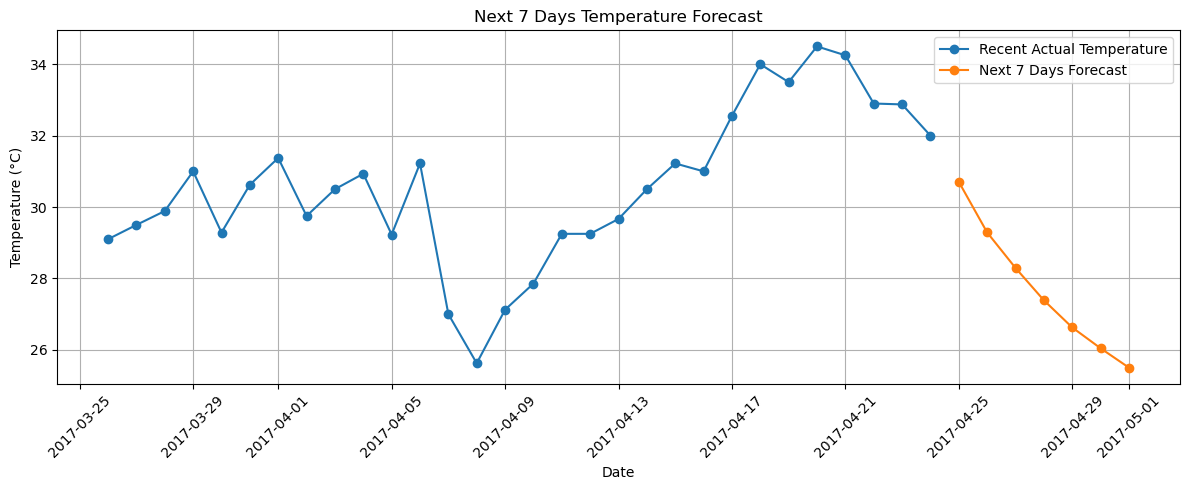

In [34]:
test_df['date'] = pd.to_datetime(test_df['date'])

future_dates = pd.date_range(
    start=test_df['date'].iloc[-1] + pd.Timedelta(days=1),
    periods=7,
    freq='D'
)

plt.figure(figsize=(12, 5))

plt.plot(
    test_df['date'].iloc[-30:],
    test_df['meantemp'].iloc[-30:],
    label='Recent Actual Temperature',
    marker='o'
)

plt.plot(
    future_dates,
    future_predictions_c,
    label='Next 7 Days Forecast',
    marker='o'
)

plt.title('Next 7 Days Temperature Forecast')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Step 32 – Save the Trained Model

In [35]:
model.save("simple_rnn_weather_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
#Step 33 – Save Forecast as CSV

In [36]:
forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted Temperature (°C)": future_predictions_c
})

forecast_df.to_csv("next_7_days_forecast.csv", index=False)

print("Forecast CSV saved successfully!")

forecast_df

Forecast CSV saved successfully!


,Date,Predicted Temperature (°C)
0,2017-04-25,30.706682
1,2017-04-26,29.288101
2,2017-04-27,28.293642
3,2017-04-28,27.388571
4,2017-04-29,26.627409
5,2017-04-30,26.044237
6,2017-05-01,25.501554
